In [1]:

from pathlib import Path

# Dataset directory (relative to the notebook location)
DATA_DIR = Path("miniImage").resolve()

# Verify the dataset directory exists
assert DATA_DIR.is_dir(), f"Dataset directory not found: {DATA_DIR}"

# print("Dataset location:", DATA_DIR)
print("Contents:", [p.name for p in DATA_DIR.iterdir()])


Contents: ['map_clsloc.txt', 'preprocess.py', 'test', 'train']


In [2]:
#If it is not downloaded uncomment this cell

# !pip -q install kagglehub

# import kagglehub
# from pathlib import Path

# # Download latest version
# DATA_DIR = Path(kagglehub.dataset_download("ctrnngtrung/miniimagenet"))

# print("Path to dataset files:", DATA_DIR)

In [3]:
import torch
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# Training: preprocessing + data augmentation
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.2, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

# Testing: preprocessing only
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),# 224 x 224 / 16 x 16 = 196 patches
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(
    DATA_DIR / "train",
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    DATA_DIR / "test",
    transform=test_transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Number of classes:", len(train_dataset.classes))

print("Same classes in both splits:",
      train_dataset.classes == test_dataset.classes)

print("First 5 classes:", train_dataset.classes[:5])

image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Pixel range:", image.min().item(), image.max().item())
print("Class index:", label)


Training images: 50000
Testing images: 10000
Number of classes: 100
Same classes in both splits: True
First 5 classes: ['n01532829', 'n01558993', 'n01704323', 'n01749939', 'n01770081']
Image shape: torch.Size([3, 224, 224])
Image dtype: torch.float32
Pixel range: 0.003921568859368563 0.9960784316062927
Class index: 0


In [4]:
# DataLoaders
from torch.utils.data import DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# Verify one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Pixel range:", images.min().item(), images.max().item())

Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
Image dtype: torch.float32
Pixel range: 0.0 1.0


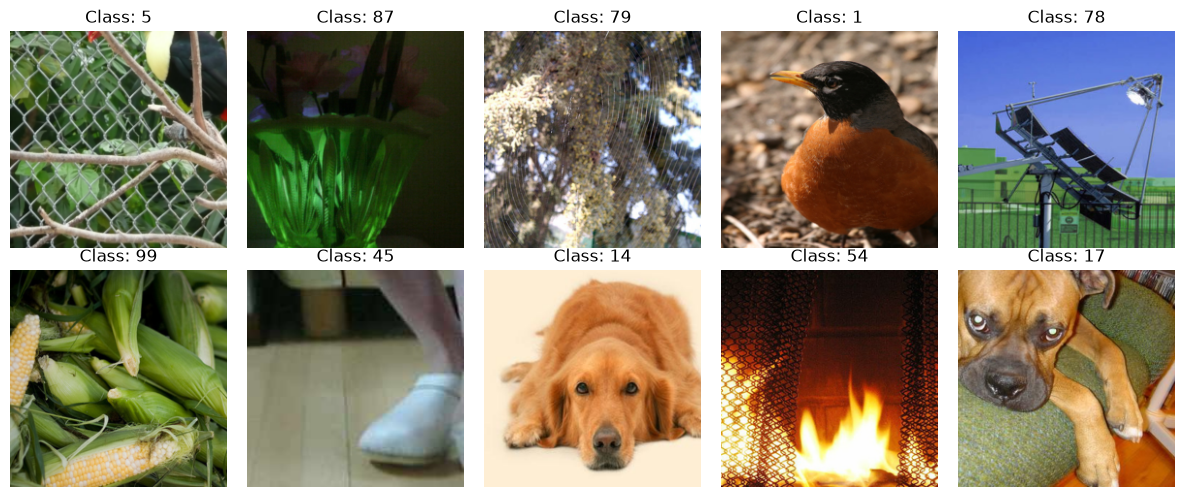

In [5]:
#Visualization

import matplotlib.pyplot as plt
import random

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Select 10 different classes
selected_classes = random.sample(
    range(len(train_dataset.classes)), 10
)

for ax, class_idx in zip(axes.flat, selected_classes):

    # Find an image belonging to the selected class
    image_idx = next(
        i for i, (_, label) in enumerate(train_dataset.samples)
        if label == class_idx
    )

    image, label = train_dataset[image_idx]

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(f"Class: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()


## Block 1: Patch Embedding

Patch embedding converts images into sequences of learnable
feature vectors (tokens) for the Vision Transformer.

1. **Patchification:** Divide each 224 × 224 RGB image into
   non-overlapping 16 × 16 patches, producing 196 patches.

2. **Linear Projection:** Each patch contains 16 × 16 × 3 = 768
   pixel values, projected into a 1024-dimensional feature
   vector (ViT-Large embedding dimension).

**Input:**  [B, 3, 224, 224]

**Output:** [B, 196, 1024]

We implement patchification and linear projection together
using a Conv2d layer with kernel_size = stride = 16.


In [6]:

import torch
import torch.nn as nn

# Patch embedding parameters
patch_size = 16
embed_dim = 1024

# Patchification + linear projection
patch_embed = nn.Conv2d(
    in_channels=3,
    out_channels=embed_dim,
    kernel_size=patch_size,
    stride=patch_size
)


In [7]:

# Get a batch from the existing DataLoader
images, labels = next(iter(train_loader))

# Apply patch embedding
x = patch_embed(images)

print("After projection:", x.shape)

# Flatten spatial dimensions and arrange as tokens
x = x.flatten(2).transpose(1, 2)

print("Patch embeddings:", x.shape)


After projection: torch.Size([64, 1024, 14, 14])
Patch embeddings: torch.Size([64, 196, 1024])



## Block 2&3: Positional Embedding & Random Masking

**Positional Embedding**
- Add fixed 2D sine-cosine positional embeddings to all 196 patches.
- Preserve spatial information without changing token dimensions.

**Random Masking**
- Randomly remove 75% of patches without replacement.
- Keep 49 visible patches and mask 147 patches.
- Save the mask and restoration indices for the decoder.


In [8]:

import numpy as np

def get_1d_sincos_pos_embed(embed_dim, positions):
    """
    positions: array of spatial coordinates
    output: [number_of_positions, embed_dim]
    """
    assert embed_dim % 2 == 0

    omega = np.arange(embed_dim // 2, dtype=np.float64)
    omega /= embed_dim / 2.0
    omega = 1.0 / (10000 ** omega)

    positions = np.asarray(positions).reshape(-1)
    angles = np.einsum("m,d->md", positions, omega)

    return np.concatenate(
        [np.sin(angles), np.cos(angles)],
        axis=1
    )


def get_2d_sincos_pos_embed(embed_dim, grid_size, cls_token=True):
    """
    Returns:
        [grid_size**2 + 1, embed_dim] if cls_token=True
    """
    assert embed_dim % 4 == 0

    grid_h = np.arange(grid_size, dtype=np.float32)
    grid_w = np.arange(grid_size, dtype=np.float32)

    grid = np.meshgrid(grid_w, grid_h)
    grid = np.stack(grid, axis=0)
    grid = grid.reshape(2, -1)

    pos_embed_h = get_1d_sincos_pos_embed(
        embed_dim // 2, grid[0]
    )
    pos_embed_w = get_1d_sincos_pos_embed(
        embed_dim // 2, grid[1]
    )

    pos_embed = np.concatenate(
        [pos_embed_h, pos_embed_w],
        axis=1
    )

    if cls_token:
        pos_embed = np.concatenate(
            [np.zeros((1, embed_dim)), pos_embed],
            axis=0
        )

    return pos_embed


In [9]:
num_patches = (224 // 16) ** 2
embed_dim = 1024

pos_embed = nn.Parameter(
    torch.zeros(1, num_patches + 1, embed_dim),
    requires_grad=False
)

pos_values = get_2d_sincos_pos_embed(
    embed_dim=embed_dim,
    grid_size=14,
    cls_token=True
)

with torch.no_grad():
    pos_embed.copy_(
        torch.from_numpy(pos_values).float().unsqueeze(0)
    )

print("Positional embedding shape:", pos_embed.shape)
print("Trainable:", pos_embed.requires_grad)


Positional embedding shape: torch.Size([1, 197, 1024])
Trainable: False


In [10]:

# Take a batch from the existing DataLoader
images, _ = next(iter(train_loader))

# Block 1: Patch embedding
x = patch_embed(images)
x = x.flatten(2).transpose(1, 2)

print("Before positional embedding:", x.shape)

# Block 2: Add positions, excluding the CLS position
x = x + pos_embed[:, 1:, :]

print("After positional embedding:", x.shape)


Before positional embedding: torch.Size([64, 196, 1024])
After positional embedding: torch.Size([64, 196, 1024])


In [11]:

def random_masking(x, mask_ratio=0.75):
    """
    x: [B, L, D] patch tokens with positional embeddings

    Returns:
        x_visible:   [B, len_keep, D]
        mask:        [B, L] (0 = visible, 1 = masked)
        ids_restore: [B, L] indices for restoring original order
    """
    if not 0 <= mask_ratio < 1:
        raise ValueError("mask_ratio must be in [0, 1).")

    B, L, D = x.shape
    len_keep = int(L * (1 - mask_ratio))

    # 1. Generate independent random scores for each image
    noise = torch.rand(B, L, device=x.device)

    # 2. Sort patch indices by their random scores
    ids_shuffle = torch.argsort(noise, dim=1)

    # 3. Compute indices for restoring original patch order
    ids_restore = torch.argsort(ids_shuffle, dim=1)

    # 4. Select indices of visible patches
    ids_keep = ids_shuffle[:, :len_keep]

    # 5. Gather only the visible patch embeddings
    x_visible = torch.gather(
        x,
        dim=1,
        index=ids_keep.unsqueeze(-1).repeat(1, 1, D)
    )

    # 6. Build mask in shuffled order
    mask = torch.ones(B, L, device=x.device)
    mask[:, :len_keep] = 0

    # 7. Restore mask to original spatial order
    mask = torch.gather(mask, dim=1, index=ids_restore)

    return x_visible, mask, ids_restore


In [12]:

x_visible, mask, ids_restore = random_masking(
    x,
    mask_ratio=0.75
)

print("Original tokens:", x.shape)
print("Visible tokens:", x_visible.shape)
print("Binary mask:", mask.shape)
print("Restoration indices:", ids_restore.shape)

print("Visible patches per image:", (mask == 0).sum(dim=1).unique())
print("Masked patches per image:", (mask == 1).sum(dim=1).unique())

assert x_visible.shape[1] == 49
assert torch.all(mask.sum(dim=1) == 147)


Original tokens: torch.Size([64, 196, 1024])
Visible tokens: torch.Size([64, 49, 1024])
Binary mask: torch.Size([64, 196])
Restoration indices: torch.Size([64, 196])
Visible patches per image: tensor([49])
Masked patches per image: tensor([147])


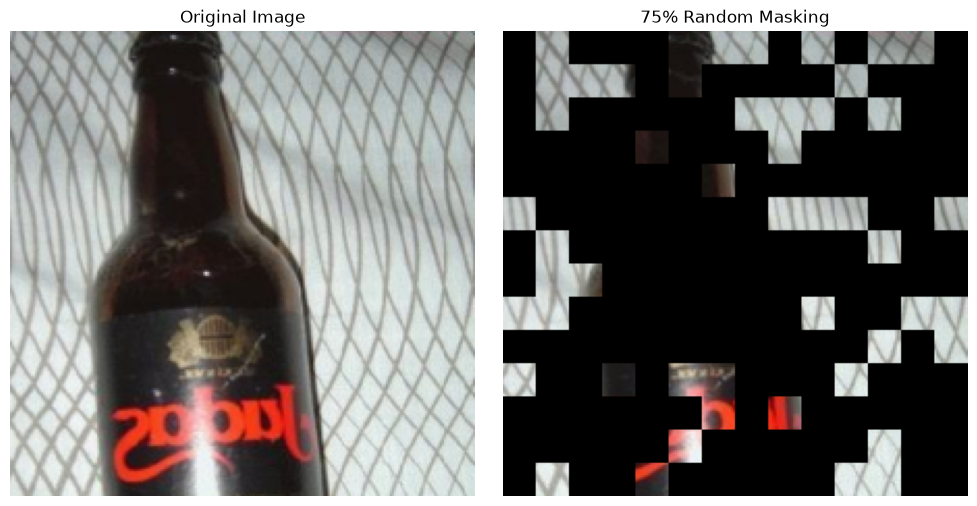

In [13]:
# First image and its corresponding mask
image = images[0].detach().cpu()
mask_grid = mask[0].reshape(14, 14).cpu()

# Expand patch mask to pixel resolution (224 × 224)
pixel_mask = mask_grid.repeat_interleave(16, dim=0).repeat_interleave(16, dim=1)

# Cover masked patches with black pixels
masked_image = image * (1 - pixel_mask.unsqueeze(0))

# Convert to image format [H, W, C]
original = image.permute(1, 2, 0).numpy()
masked = masked_image.permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original.clip(0, 1))
axes[0].set_title("Original Image")

axes[1].imshow(masked.clip(0, 1))
axes[1].set_title("75% Random Masking")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()



### Block 4.1: CLS Token Preparation

The MAE encoder receives 49 visible patch embeddings, each with
1024 features.

Before the Transformer blocks, we prepend a learnable
classification token (CLS) to the sequence.

The CLS token:
- Has the same embedding dimension as the patch tokens (1024).
- Is initialized with random values from N(0, 0.02²).
- Is updated through backpropagation during training.
- Receives its own fixed positional embedding.

**Operation:**

CLS = learnable_cls_token + cls_positional_embedding

Encoder_Input = Concatenate(CLS, Visible_Patches)

**Input:**  [B, 49, 1024]

**Output:** [B, 50, 1024]

The CLS token is added after random masking, following the
official MAE implementation.


In [ ]:
embed_dim = 1024

# One learnable CLS token
cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))

# Initialize as in the official MAE implementation
nn.init.normal_(cls_token, std=0.02)

print("CLS token shape:", cls_token.shape)
print("Trainable:", cls_token.requires_grad)


CLS token shape: torch.Size([1, 1, 1024])
Trainable: True


In [15]:

# Number of images in the current batch
B = x_visible.shape[0]

# Add the CLS positional embedding
cls = cls_token + pos_embed[:, :1, :]

# Expand CLS token across the batch
cls_tokens = cls.expand(B, -1, -1)

# Prepend CLS token to the visible patch sequence
encoder_input = torch.cat(
    [cls_tokens, x_visible],
    dim=1
)

print("Visible patches:", x_visible.shape)
print("CLS tokens:", cls_tokens.shape)
print("Encoder input:", encoder_input.shape)


Visible patches: torch.Size([64, 49, 1024])
CLS tokens: torch.Size([64, 1, 1024])
Encoder input: torch.Size([64, 50, 1024])


In [16]:

# Verify dimensions
assert encoder_input.shape == (
    x_visible.shape[0], 50, 1024
)

# First token must be the CLS token
assert torch.allclose(
    encoder_input[:, :1, :],
    cls_tokens
)

# Remaining tokens must be unchanged visible patches
assert torch.allclose(
    encoder_input[:, 1:, :],
    x_visible
)

print("CLS token correctly prepended.")
print("Encoder input ready:", encoder_input.shape)


CLS token correctly prepended.
Encoder input ready: torch.Size([64, 50, 1024])



### Block 4.2: Transformer Encoder Block Overview

A Transformer encoder block combines Multi-Head Self-Attention (MHSA) and a Feed-Forward Network (MLP), using Layer Normalization and residual connections.

The input consists of 50 tokens: one CLS token and 49 visible image patches. Each token has 1024 features.

**Workflow:**

1. **LayerNorm 1:** Normalizes the input token features.
2. **MHSA:** Allows tokens to gather contextual information from other visible tokens.
3. **Residual Connection 1:** Adds the attention output to the original block input.
4. **LayerNorm 2:** Normalizes the features before the MLP.
5. **MLP:** Expands the feature dimension from 1024 to 4096, applies GELU, and projects back to 1024.
6. **Residual Connection 2:** Adds the MLP output to the first residual output.


**Input:** `[B, 50, 1024]`

**Output:** `[B, 50, 1024]`

The Transformer block updates token representations without changing the number of tokens or their embedding dimensions.

In MAE ViT-Large, the encoder contains 24 such Transformer blocks, each with independent learnable parameters.

At this stage, the operations have been demonstrated separately. They will subsequently be encapsulated in a reusable `nn.Module` and stacked to construct the complete encoder.



### Block 4.2.1: Layer Normalization 1 (LayerNorm)

https://docs.pytorch.org/docs/2.15/generated/torch.nn.LayerNorm.html

LayerNorm normalizes the 1024 features of each token independently.

It makes the feature values more consistently scaled, helping the
Transformer train stably, especially across many layers.

For each token, LayerNorm:

1. Calculates the mean and variance of its 1024 features.
2. Centers and scales those features.
3. Applies two learnable parameters: gamma (scale) and beta (shift).

LayerNorm does not combine information from different
tokens. Each token is normalized independently.

MAE uses Pre-LayerNorm: normalization happens before self-attention
and before the MLP.

Input:  [B, 50, 1024]
Output: [B, 50, 1024]


In [17]:
# First LayerNorm of the Transformer encoder block
norm1 = nn.LayerNorm(
    normalized_shape=1024,
    eps=1e-6,
    elementwise_affine=True
)

print(norm1)


LayerNorm((1024,), eps=1e-06, elementwise_affine=True, bias=True)


In [18]:

# Input from Block 4.1
print("Before LayerNorm:", encoder_input.shape)

# Apply normalization
x_norm1 = norm1(encoder_input)

print("After LayerNorm:", x_norm1.shape)


Before LayerNorm: torch.Size([64, 50, 1024])
After LayerNorm: torch.Size([64, 50, 1024])


In [19]:

# Examine the first patch token in the first image
token_before = encoder_input[0, 1, :]
token_after = x_norm1[0, 1, :]

print("Before normalization:")
print("Mean:", token_before.mean().item())
print("Std:", token_before.std(unbiased=False).item())

print("\nAfter normalization:")
print("Mean:", token_after.mean().item())
print("Std:", token_after.std(unbiased=False).item())

# Verify that LayerNorm preserves tensor dimensions
assert x_norm1.shape == encoder_input.shape


Before normalization:
Mean: 0.48815852403640747
Std: 0.6739198565483093

After normalization:
Mean: 4.284083843231201e-08
Std: 0.999998927116394



### Block 4.2.2: Multi-Head Self-Attention (MHSA)

Multi-Head Self-Attention allows each token to gather information
from every other token in the sequence.

In MAE ViT-Large, the input contains:
- 1 CLS token + 49 visible patch tokens = 50 tokens
- 1024 features per token
- 16 parallel attention heads
- 64 features per head (1024 / 16)

**Process:**

1. Project input tokens into Query (Q), Key (K), and Value (V).
2. Split Q, K, and V into 16 attention heads.
3. Compute attention scores using Q × Kᵀ / sqrt(64).
4. Apply Softmax to obtain attention weights.
5. Multiply attention weights by V to aggregate information.
6. Concatenate the 16 heads.
7. Apply a final learned linear projection.

**Formula:**

Attention(Q, K, V) = Softmax(QKᵀ / sqrt(d_head)) × V

MHSA(X) = Concat(head_1, ..., head_16) × W_output + bias

**Input:**  [B, 50, 1024]
**Output:** [B, 50, 1024]

Attention changes the token representations, not their dimensions.

Only the 49 visible patches and CLS token participate.
The 147 masked patches are not processed by the encoder.


In [20]:

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim=1024, num_heads=16):
        super().__init__()

        assert embed_dim % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.scale = self.head_dim ** -0.5

        # Combined linear projection for Q, K, V
        self.qkv = nn.Linear(
            embed_dim,
            3 * embed_dim,
            bias=True
        )

        # Final output projection
        self.proj = nn.Linear(embed_dim, embed_dim)

        # Initialization used by the original MAE model
        nn.init.xavier_uniform_(self.qkv.weight)
        nn.init.zeros_(self.qkv.bias)
        nn.init.xavier_uniform_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x):
        B, N, D = x.shape

        # 1. Compute Q, K, V
        qkv = self.qkv(x)  # [B, N, 3*D]

        # 2. Split into attention heads
        qkv = qkv.reshape(
            B, N, 3, self.num_heads, self.head_dim
        )
        qkv = qkv.permute(2, 0, 3, 1, 4)

        q, k, v = qkv.unbind(0)
        # Each: [B, num_heads, N, head_dim]

        # 3. Scaled dot-product attention scores
        scores = (q @ k.transpose(-2, -1)) * self.scale

        # 4. Convert scores to attention weights
        attn_weights = scores.softmax(dim=-1)

        # 5. Weighted sum of Value vectors
        out = attn_weights @ v

        # 6. Concatenate the attention heads
        out = out.transpose(1, 2).reshape(B, N, D)

        # 7. Final output projection
        out = self.proj(out)

        return out


In [21]:

embed_dim = 1024
num_heads = 16

mhsa = MultiHeadSelfAttention(
    embed_dim=embed_dim,
    num_heads=num_heads
).to(x_norm1.device)

print("Number of heads:", mhsa.num_heads)
print("Dimension per head:", mhsa.head_dim)
print("Attention scaling factor:", mhsa.scale)


Number of heads: 16
Dimension per head: 64
Attention scaling factor: 0.125


In [22]:

# Input from LayerNorm 1
print("Input:", x_norm1.shape)

# Apply Multi-Head Self-Attention
x_attn = mhsa(x_norm1)

print("MHSA output:", x_attn.shape)


Input: torch.Size([64, 50, 1024])


MHSA output: torch.Size([64, 50, 1024])


In [23]:

B, N, D = x_norm1.shape

with torch.no_grad():
    # Combined Q, K, V projection
    qkv = mhsa.qkv(x_norm1)

    # Reshape and separate heads
    qkv = qkv.reshape(B, N, 3, 16, 64)
    qkv = qkv.permute(2, 0, 3, 1, 4)

    q, k, v = qkv.unbind(0)

    # Attention scores
    scores = (q @ k.transpose(-2, -1)) * mhsa.scale

    # Attention weights
    attention_weights = scores.softmax(dim=-1)

print("Q:", q.shape)
print("K:", k.shape)
print("V:", v.shape)
print("Attention scores:", scores.shape)
print("Attention weights:", attention_weights.shape)


Q: torch.Size([64, 16, 50, 64])
K: torch.Size([64, 16, 50, 64])
V: torch.Size([64, 16, 50, 64])
Attention scores: torch.Size([64, 16, 50, 50])
Attention weights: torch.Size([64, 16, 50, 50])


In [24]:

# Check output dimensions
assert x_attn.shape == x_norm1.shape

# Every attention distribution sums to 1
weight_sums = attention_weights.sum(dim=-1)

assert torch.allclose(
    weight_sums,
    torch.ones_like(weight_sums),
    atol=1e-5
)

# Check that outputs contain no NaN or infinite values
assert torch.isfinite(x_attn).all()

print("Attention weights sum to:",
      weight_sums[0, 0, 0].item())

print("All MHSA checks passed.")


Attention weights sum to: 1.0000001192092896
All MHSA checks passed.



### Block 4.2.3: First Residual Connection

After Multi-Head Self-Attention, the original encoder input is added to the attention output.

This residual (skip) connection preserves the original token information while incorporating contextual information obtained through self-attention.

It also provides a direct path for gradient propagation, helping stabilize training in deep Transformers.


The skip connection uses the original, unnormalized encoder input, following the pre-norm ViT architecture.

**Input:** Two tensors of shape `[B, 50, 1024]`

**Output:** `[B, 50, 1024]`

No new learnable parameters are introduced.


In [25]:

# First residual connection
# Add the original encoder input to the attention output

x_residual1 = encoder_input + x_attn

print("Encoder input:", encoder_input.shape)
print("Attention output:", x_attn.shape)
print("First residual output:", x_residual1.shape)

# Verify that the dimensions are preserved
assert x_residual1.shape == encoder_input.shape

print("First residual connection passed.")


Encoder input: torch.Size([64, 50, 1024])
Attention output: torch.Size([64, 50, 1024])
First residual output: torch.Size([64, 50, 1024])
First residual connection passed.



### Block 4.2.4: Layer Normalization 2 (LayerNorm)

The output of the first residual connection is normalized before entering the MLP.

LayerNorm operates independently on the 1024 features of each token.

For each token, it:

1. Computes the mean and variance of its features.
2. Normalizes the features using these statistics.
3. Applies learnable scale (gamma) and shift (beta) parameters.

The second LayerNorm has its own learnable parameters and is separate from LayerNorm 1.



MAE uses pre-layer normalization, so normalization occurs before the MLP.

**Input:** `[B, 50, 1024]`

**Output:** `[B, 50, 1024]`


In [26]:

# Second LayerNorm of the Transformer encoder block
norm2 = nn.LayerNorm(
    normalized_shape=1024,
    eps=1e-6,
    elementwise_affine=True
).to(x_residual1.device)

# Normalize the output of the first residual connection
x_norm2 = norm2(x_residual1)

print("Before LayerNorm 2:", x_residual1.shape)
print("After LayerNorm 2:", x_norm2.shape)

# Verify dimensions and numerical validity
assert x_norm2.shape == x_residual1.shape
assert torch.isfinite(x_norm2).all()

print("Second LayerNorm passed.")


Before LayerNorm 2: torch.Size([64, 50, 1024])
After LayerNorm 2: torch.Size([64, 50, 1024])
Second LayerNorm passed.



### Block 4.2.5: Feed-Forward Network (MLP)

The MLP transforms the features of each token independently after self-attention.

Unlike Multi-Head Self-Attention, the MLP does not exchange information between tokens.

The ViT-Large MLP contains:

1. Linear projection from 1024 to 4096 features.
2. GELU nonlinear activation.
3. Linear projection from 4096 back to 1024 features.

The hidden dimension is four times the embedding dimension.


The input and output embedding dimensions remain 1024.

**Input:** `[B, 50, 1024]`

**Hidden representation:** `[B, 50, 4096]`

**Output:** `[B, 50, 1024]`

The MLP contains learnable weights and biases.


In [27]:

class MLP(nn.Module):
    def __init__(self, embed_dim=1024, mlp_ratio=4):
        super().__init__()

        hidden_dim = int(embed_dim * mlp_ratio)

        # Expand feature dimension: 1024 -> 4096
        self.fc1 = nn.Linear(embed_dim, hidden_dim)

        # Nonlinear activation
        self.act = nn.GELU()

        # Project feature dimension back: 4096 -> 1024
        self.fc2 = nn.Linear(hidden_dim, embed_dim)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.fc2(x)

        return x


In [28]:

# Create the MLP for ViT-Large
mlp = MLP(
    embed_dim=1024,
    mlp_ratio=4
).to(x_norm2.device)

# Apply MLP to normalized tokens
x_mlp = mlp(x_norm2)

print("MLP input:", x_norm2.shape)
print("MLP output:", x_mlp.shape)

# Verify the expansion and projection dimensions
assert mlp.fc1.in_features == 1024
assert mlp.fc1.out_features == 4096
assert mlp.fc2.in_features == 4096
assert mlp.fc2.out_features == 1024

# Verify output shape and finite values
assert x_mlp.shape == x_norm2.shape
assert torch.isfinite(x_mlp).all()

print("MLP checks passed.")


MLP input: torch.Size([64, 50, 1024])
MLP output: torch.Size([64, 50, 1024])
MLP checks passed.



### Block 4.2.6: Second Residual Connection

The MLP output is added to the input of the MLP sublayer, before LayerNorm 2 was applied.

This residual connection preserves the information in the first residual output while incorporating the nonlinear feature transformations produced by the MLP.

Like the first residual connection, it provides an identity path that supports gradient propagation through deep Transformer networks.



This operation completes the computation of one pre-norm Transformer encoder block.

**Input:** Two tensors of shape `[B, 50, 1024]`

**Output:** `[B, 50, 1024]`

No new learnable parameters are introduced.

The resulting tensor is ready to become the input of the next Transformer encoder block.


In [29]:

# Second residual connection
# Add the MLP output to the first residual output

x_block = x_residual1 + x_mlp

print("First residual output:", x_residual1.shape)
print("MLP output:", x_mlp.shape)
print("Transformer block output:", x_block.shape)

# Verify dimensions and numerical validity
assert x_block.shape == encoder_input.shape
assert torch.isfinite(x_block).all()

print("One Transformer encoder block computation completed.")


First residual output: torch.Size([64, 50, 1024])
MLP output: torch.Size([64, 50, 1024])
Transformer block output: torch.Size([64, 50, 1024])
One Transformer encoder block computation completed.



### Block 4.3: Reusable Transformer Encoder Block

The previous sections implemented LayerNorm, Multi-Head Self-Attention (MHSA), the MLP, and residual connections separately.

We now encapsulate these operations into a reusable `TransformerEncoderBlock(nn.Module)`.

Each block contains four independent trainable submodules:

1. **LayerNorm 1:** Normalizes token features before attention.
2. **Multi-Head Self-Attention:** Exchanges contextual information among the visible tokens.
3. **LayerNorm 2:** Normalizes token features before the MLP.
4. **MLP:** Applies a nonlinear feature transformation with GELU.

Two residual connections preserve information and support gradient propagation.

The block uses the **pre-norm** formulation of Vision Transformer:



For MAE ViT-Large:

- Embedding dimension: 1024
- Attention heads: 16
- Dimension per head: 64
- MLP hidden dimension: 4096
- Normalization epsilon: \(10^{-6}\)

**Input:** `[B, 50, 1024]`

**Output:** `[B, 50, 1024]`

The block updates token representations without changing the token count or embedding width. It can be instantiated repeatedly with independent parameters.


In [30]:

#Reusable Transformer Encoder Block

import torch
import torch.nn as nn


class MLP(nn.Module):
    def __init__(self, embed_dim=1024, mlp_ratio=4.0):
        super().__init__()

        hidden_dim = int(embed_dim * mlp_ratio)

        # Expand token features: 1024 -> 4096
        self.fc1 = nn.Linear(embed_dim, hidden_dim)

        # Nonlinear activation
        self.act = nn.GELU()

        # Restore token features: 4096 -> 1024
        self.fc2 = nn.Linear(hidden_dim, embed_dim)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.fc2(x)

        return x


class TransformerEncoderBlock(nn.Module):
    def __init__(
        self,
        embed_dim=1024,
        num_heads=16,
        mlp_ratio=4.0
    ):
        super().__init__()

        # Attention sublayer
        self.norm1 = nn.LayerNorm(embed_dim, eps=1e-6)

        self.attn = MultiHeadSelfAttention(
            embed_dim=embed_dim,
            num_heads=num_heads
        )

        # Feed-forward sublayer
        self.norm2 = nn.LayerNorm(embed_dim, eps=1e-6)

        self.mlp = MLP(
            embed_dim=embed_dim,
            mlp_ratio=mlp_ratio
        )

    def forward(self, x):

        # Sublayer 1: Pre-norm MHSA + residual
        x = x + self.attn(self.norm1(x))

        # Sublayer 2: Pre-norm MLP + residual
        x = x + self.mlp(self.norm2(x))

        return x


In [31]:

#Verify one reusable Transformer block

torch.manual_seed(42)

# Small configuration for testing the implementation
test_block = TransformerEncoderBlock(
    embed_dim=64,
    num_heads=4,
    mlp_ratio=4.0
)

# Two images, seven tokens, 64 features per token
test_input = torch.randn(
    2, 7, 64,
    requires_grad=True
)

test_output = test_block(test_input)

print("Input shape:", test_input.shape)
print("Output shape:", test_output.shape)

assert test_output.shape == test_input.shape
assert torch.isfinite(test_output).all()

# Verify equivalence to the explicit residual equations
z = test_input + test_block.attn(
    test_block.norm1(test_input)
)

manual_output = z + test_block.mlp(
    test_block.norm2(z)
)

assert torch.allclose(
    test_output,
    manual_output,
    atol=1e-6,
    rtol=1e-5
)

# Verify backward propagation
loss = test_output.square().mean()
loss.backward()

assert test_input.grad is not None
assert torch.isfinite(test_input.grad).all()

for name, param in test_block.named_parameters():
    assert param.grad is not None, (
        f"Missing gradient: {name}"
    )
    assert torch.isfinite(param.grad).all(), (
        f"Invalid gradient: {name}"
    )

print("Block forward and backward checks passed.")


Input shape: torch.Size([2, 7, 64])
Output shape: torch.Size([2, 7, 64])
Block forward and backward checks passed.



### Block 4.4: Complete MAE Vision Transformer Encoder

The MAE encoder converts an image into contextual latent representations using a Vision Transformer.

Unlike a conventional ViT used for classification, the MAE encoder processes only visible image patches during self-supervised pretraining.

The encoder performs the following operations:

1. **Patch Embedding:** Divide the 224×224 RGB image into 196 patches of size 16×16 and project each patch into 1024 features.
2. **Positional Embedding:** Add fixed 2D sine/cosine positional embeddings to the patch tokens.
3. **Random Masking:** Remove 75% of patches, retaining 49 visible patch tokens.
4. **CLS Token:** Prepend one learnable CLS token, producing a sequence of 50 tokens.
5. **Transformer Stack:** Process the sequence through 24 independent pre-norm Transformer encoder blocks.
6. **Final LayerNorm:** Normalize the final token representations.

**Architecture:**

- Image resolution: 224×224
- Patch size: 16×16
- Encoder embedding dimension: 1024
- Transformer depth: 24
- Attention heads: 16
- MLP expansion ratio: 4
- Training mask ratio: 75%

**Tensor flow:**

```text
Input image             [B, 3, 224, 224]
Patch embeddings        [B, 196, 1024]
Position-aware patches  [B, 196, 1024]
Visible patch tokens    [B, 49, 1024]
CLS + visible tokens    [B, 50, 1024]
24 Transformer blocks   [B, 50, 1024]
Final LayerNorm         [B, 50, 1024]
```

The encoder returns:

- `latent`: Encoded CLS token and visible patch tokens.
- `mask`: Binary spatial mask (0 = visible, 1 = masked).
- `ids_restore`: Indices required to restore the original patch order in the decoder.

All trainable components are registered inside `nn.Module`, and all 24 Transformer blocks have independent parameters.

During downstream classification, the same encoder can operate without masking, processing all 196 patches plus the CLS token.


In [32]:

#Complete MAE ViT Encoder

class MAEEncoder(nn.Module):
    def __init__(
        self,
        img_size=224,
        patch_size=16,
        in_chans=3,
        embed_dim=1024,
        depth=24,
        num_heads=16,
        mlp_ratio=4.0
    ):
        super().__init__()

        assert img_size % patch_size == 0
        assert embed_dim % num_heads == 0

        grid_size = img_size // patch_size
        num_patches = grid_size ** 2

        self.img_size = img_size
        self.patch_size = patch_size
        self.embed_dim = embed_dim
        self.num_patches = num_patches

        # 1. Patch embedding
        self.patch_embed = nn.Conv2d(
            in_channels=in_chans,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # 2. Learnable CLS token
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        # 3. Fixed 2D sine/cosine positional embeddings
        pos_values = get_2d_sincos_pos_embed(
            embed_dim=embed_dim,
            grid_size=grid_size,
            cls_token=True
        )

        # Register fixed positions as a non-trainable buffer
        self.register_buffer(
            "pos_embed",
            torch.from_numpy(pos_values)
                 .float()
                 .unsqueeze(0),
            persistent=True
        )

        # 4. Stack of independent Transformer blocks
        self.blocks = nn.ModuleList([
            TransformerEncoderBlock(
                embed_dim=embed_dim,
                num_heads=num_heads,
                mlp_ratio=mlp_ratio
            )
            for _ in range(depth)
        ])

        # 5. Final encoder normalization
        self.norm = nn.LayerNorm(
            embed_dim,
            eps=1e-6
        )

        # Parameter initialization
        nn.init.normal_(self.cls_token, std=0.02)

        # Initialize patch projection as a linear projection
        nn.init.xavier_uniform_(
            self.patch_embed.weight.view(embed_dim, -1)
        )

        if self.patch_embed.bias is not None:
            nn.init.zeros_(self.patch_embed.bias)

    def forward(self, images, mask_ratio=0.75):

        B = images.shape[0]

        if (
            images.ndim != 4
            or images.shape[2:] != (
                self.img_size, self.img_size
            )
        ):
            raise ValueError(
                "Expected images with shape "
                "[B, C, img_size, img_size]."
            )

        # Step 1: Patch embedding
        x = self.patch_embed(images)

        # [B, D, 14, 14] -> [B, 196, D]
        x = x.flatten(2).transpose(1, 2)

        # Step 2: Add patch positional embeddings
        # Exclude the CLS positional slot for now
        x = x + self.pos_embed[:, 1:, :]

        # Step 3: Random masking
        # Only visible patches continue into the encoder
        x, mask, ids_restore = random_masking(
            x,
            mask_ratio=mask_ratio
        )

        # Step 4: Prepare CLS token
        cls = (
            self.cls_token + self.pos_embed[:, :1, :]
        ).expand(B, -1, -1)

        # Prepend CLS to visible patches
        x = torch.cat([cls, x], dim=1)

        # Step 5: 24 independent Transformer blocks
        for block in self.blocks:
            x = block(x)

        # Step 6: Final encoder LayerNorm
        x = self.norm(x)

        return x, mask, ids_restore


In [33]:

#Lightweight 24-block architecture test

torch.manual_seed(42)

test_encoder = MAEEncoder(
    img_size=224,
    patch_size=16,
    in_chans=3,
    embed_dim=64,
    depth=24,
    num_heads=4,
    mlp_ratio=4.0
)

# Verify exactly 24 registered Transformer blocks
assert len(test_encoder.blocks) == 24

# Verify the block objects are independent
block_ids = [
    id(block) for block in test_encoder.blocks
]

assert len(set(block_ids)) == 24

# Verify attention QKV weight storage is not shared
qkv_addresses = [
    block.attn.qkv.weight.data_ptr()
    for block in test_encoder.blocks
]

assert len(set(qkv_addresses)) == 24

# Fixed position embeddings must not be trainable
assert "pos_embed" not in dict(
    test_encoder.named_parameters()
)

# One example image
test_images = torch.randn(1, 3, 224, 224)

# Evaluate without storing the backward graph
test_encoder.eval()

with torch.no_grad():
    latent, mask, ids_restore = test_encoder(
        test_images,
        mask_ratio=0.75
    )

print("Transformer blocks:", len(test_encoder.blocks))
print("Encoder output:", latent.shape)
print("Mask:", mask.shape)
print("Restoration indices:", ids_restore.shape)
print("Masked patches:", int(mask.sum().item()))

assert latent.shape == (1, 50, 64)
assert mask.shape == (1, 196)
assert ids_restore.shape == (1, 196)
assert int(mask.sum().item()) == 147
assert torch.isfinite(latent).all()

print("24 independent encoder blocks verified.")


Transformer blocks: 24
Encoder output: torch.Size([1, 50, 64])
Mask: torch.Size([1, 196])
Restoration indices: torch.Size([1, 196])
Masked patches: 147
24 independent encoder blocks verified.


In [34]:

#Integrated encoder gradient test

gradient_encoder = MAEEncoder(
    img_size=224,
    patch_size=16,
    embed_dim=64,
    depth=2,
    num_heads=4
)

gradient_encoder.train()

small_images = torch.randn(1, 3, 224, 224)

latent, mask, ids_restore = gradient_encoder(
    small_images,
    mask_ratio=0.75
)

# Diagnostic loss for checking gradient flow only
diagnostic_loss = latent.square().mean()

gradient_encoder.zero_grad(set_to_none=True)
diagnostic_loss.backward()

# Verify gradients exist for all trainable parameters
for name, param in gradient_encoder.named_parameters():
    assert param.grad is not None, (
        f"Missing gradient for: {name}"
    )
    assert torch.isfinite(param.grad).all(), (
        f"Non-finite gradient for: {name}"
    )

# Explicitly verify key components
assert gradient_encoder.patch_embed.weight.grad is not None
assert gradient_encoder.cls_token.grad is not None

print("Integrated encoder forward/backward test passed.")
print("Trainable parameters receive finite gradients.")


Integrated encoder forward/backward test passed.
Trainable parameters receive finite gradients.


In [35]:

#Full MAE ViT-Large encoder

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

mae_encoder = MAEEncoder(
    img_size=224,
    patch_size=16,
    in_chans=3,
    embed_dim=1024,
    depth=24,
    num_heads=16,
    mlp_ratio=4.0
).to(device)

# Check architecture and model parameter count
num_parameters = sum(
    p.numel() for p in mae_encoder.parameters()
)

print("Device:", device)
print("Encoder blocks:", len(mae_encoder.blocks))
print("Embedding dimension:", mae_encoder.embed_dim)
print("Patch count:", mae_encoder.num_patches)
print(f"Trainable parameters: {num_parameters:,}")


Device: cpu
Encoder blocks: 24
Embedding dimension: 1024
Patch count: 196
Trainable parameters: 303,099,904


In [39]:

# Full ViT-Large encoder forward smoke test
# Run only if sufficient memory is available.

mae_encoder.eval()

with torch.inference_mode():
    sample = torch.randn(
        1, 3, 224, 224,
        device=device
    )

    latent, mask, ids_restore = mae_encoder(
        sample,
        mask_ratio=0.75
    )

assert latent.shape == (1, 50, 1024)
assert mask.shape == (1, 196)
assert ids_restore.shape == (1, 196)
assert int(mask.sum().item()) == 147

print("Full encoder output:", latent.shape)
print("Full ViT-Large forward test passed.")


Full encoder output: torch.Size([1, 50, 1024])
Full ViT-Large forward test passed.


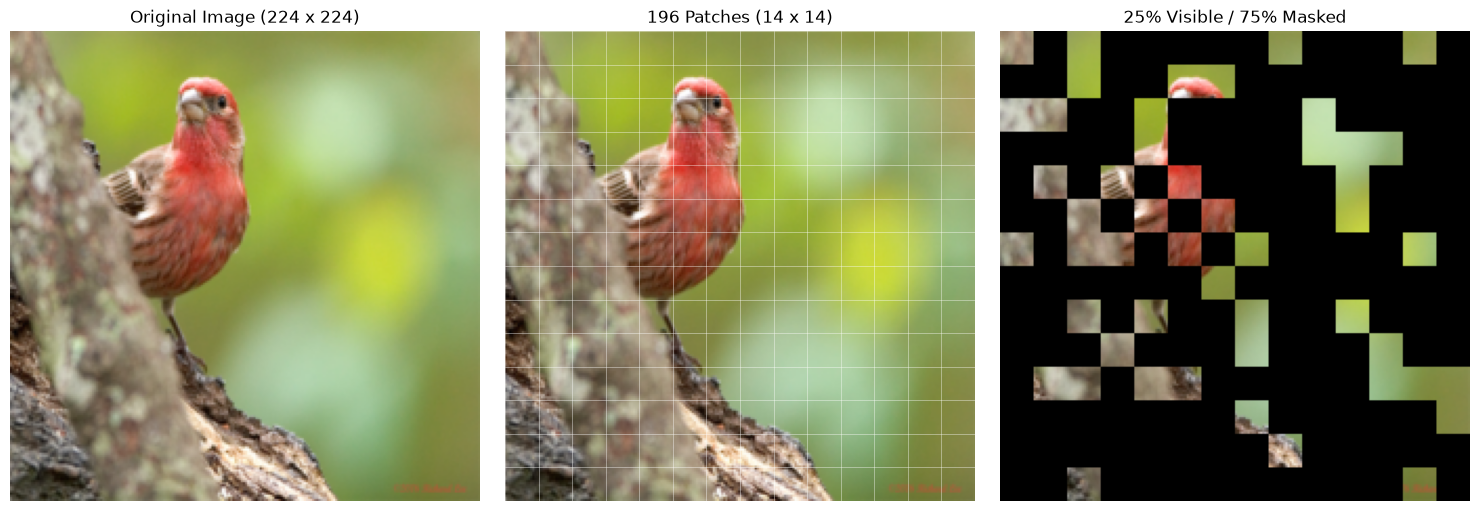

Total patches: 196
Visible patches: 49
Masked patches: 147
Encoder output: torch.Size([1, 50, 1024])


In [45]:

# Block 4.5.1 — Visualize original and masked image

import torch
import matplotlib.pyplot as plt
import numpy as np

# Use a deterministic test image
image, label = test_dataset[0]

# Add the batch dimension and move to model device
image_batch = image.unsqueeze(0).to(device)

mae_encoder.eval()

with torch.inference_mode():
    latent_vis, mask_vis, ids_restore_vis = mae_encoder(
        image_batch,
        mask_ratio=0.75
    )

# Mask: 0 = visible, 1 = removed
mask_grid = mask_vis[0].reshape(14, 14).cpu()

# Expand from 14x14 patches to 224x224 pixels
pixel_mask = mask_grid.repeat_interleave(
    16, dim=0
).repeat_interleave(
    16, dim=1
)

# Black out the masked patches
masked_image = image * (1 - pixel_mask.unsqueeze(0))

original_np = image.permute(1, 2, 0).numpy()
masked_np = masked_image.permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original image
axes[0].imshow(original_np)
axes[0].set_title("Original Image (224 x 224)")

# Original image with patch grid
axes[1].imshow(original_np)

for p in range(0, 225, 16):
    axes[1].axhline(p - 0.5, color="white",
                    linewidth=0.4, alpha=0.7)
    axes[1].axvline(p - 0.5, color="white",
                    linewidth=0.4, alpha=0.7)

axes[1].set_title("196 Patches (14 x 14)")

# 75% masked image
axes[2].imshow(masked_np)
axes[2].set_title("25% Visible / 75% Masked")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Numerical verification
num_visible = int((mask_vis == 0).sum().item())
num_masked = int((mask_vis == 1).sum().item())

print("Total patches:", mask_vis.shape[1])
print("Visible patches:", num_visible)
print("Masked patches:", num_masked)
print("Encoder output:", latent_vis.shape)

assert num_visible == 49
assert num_masked == 147
assert latent_vis.shape == (1, 50, 1024)


In [48]:

# Block 4.5.2 — Display the actual encoder representation
# Uses the SAME image and masking from Block 4.5.1

import numpy as np
import matplotlib.pyplot as plt

# Extract the encoder output for the selected image
encoded_matrix = latent_vis[0].detach().cpu().numpy()

# Display numerical values with 4 decimal places
np.set_printoptions(
    precision=4,
    suppress=True,
    linewidth=160,
    threshold=120,
    edgeitems=4
)

print("=" * 70)
print("ACTUAL ENCODER OUTPUT MATRIX")
print("=" * 70)

print("\nMatrix shape:", encoded_matrix.shape)
print("Rows: 1 CLS token + 49 visible patch tokens")
print("Columns: 1024 features per token\n")

print(encoded_matrix)

print("\n" + "=" * 70)
print("CLS TOKEN  1024-dimensional vector")
print("=" * 70)
print(encoded_matrix[0])

print("\n" + "=" * 70)
print("FIRST VISIBLE PATCH  1024-dimensional vector")
print("=" * 70)
print(encoded_matrix[1])

# Verify the matrix
assert encoded_matrix.shape == (50, 1024)
assert np.isfinite(encoded_matrix).all()

print("\nEncoder matrix verified.")


ACTUAL ENCODER OUTPUT MATRIX

Matrix shape: (50, 1024)
Rows: 1 CLS token + 49 visible patch tokens
Columns: 1024 features per token

[[-1.4264  0.9843 -2.1028 -0.4111 ... -1.0919  0.2804  0.0063  1.7082]
 [-1.5081  0.7773 -2.1113 -0.2637 ... -0.9327  0.3238  0.3479  1.66  ]
 [-1.6462  0.6486 -2.1343 -0.3236 ... -1.0122  0.3577  0.1934  1.7699]
 [-1.7086  0.7526 -2.2098 -0.2971 ... -1.0061  0.3131  0.2352  1.7597]
 ...
 [-1.8752  0.4906 -2.4712 -0.5619 ... -0.9792  0.3887  0.1653  1.8944]
 [-1.4321  0.9089 -1.989  -0.1802 ... -1.0494  0.2101  0.3394  1.6688]
 [-1.9721  0.3267 -2.4967 -0.6395 ... -0.9267  0.4054  0.287   1.7155]
 [-1.8125  0.4014 -2.5643 -0.6239 ... -0.9496  0.3542  0.3441  1.6458]]

CLS TOKEN  1024-dimensional vector
[-1.4264  0.9843 -2.1028 -0.4111 ... -1.0919  0.2804  0.0063  1.7082]

FIRST VISIBLE PATCH  1024-dimensional vector
[-1.5081  0.7773 -2.1113 -0.2637 ... -0.9327  0.3238  0.3479  1.66  ]

Encoder matrix verified.



## Block 5:  Decoder

The MAE decoder reconstructs masked image patches using the contextual representations produced by the Vision Transformer encoder.

The encoder processes only visible patches to reduce computation. The decoder receives the encoded visible tokens, inserts learnable mask tokens for the missing patches, and restores the original spatial order.

The decoder consists of:

1. **Encoder-to-decoder projection:** Reduces the embedding dimension from 1024 to 512.
2. **Mask token insertion:** Introduces learnable representations for the 147 masked patches.
3. **Patch-order restoration:** Uses `ids_restore` to return tokens to their original 14×14 spatial positions.
4. **Decoder positional embeddings:** Adds fixed 2D sine-cosine positional information.
5. **Transformer decoder:** Processes all tokens through 8 Transformer blocks.
6. **Pixel prediction:** Predicts the 768 RGB pixel values of each 16×16 image patch.

**Architecture:**

- Encoder embedding dimension: 1024
- Decoder embedding dimension: 512
- Decoder depth: 8 Transformer blocks
- Decoder attention heads: 16
- MLP expansion ratio: 4
- Patch size: 16×16
- Number of image patches: 196

**Tensor flow:**

```text
Encoder latent              [B, 50, 1024]
Linear projection           [B, 50, 512]
Insert 147 mask tokens      [B, 197, 512]
Restore original positions  [B, 197, 512]
Add positional embeddings   [B, 197, 512]
8 Transformer blocks        [B, 197, 512]
Final LayerNorm             [B, 197, 512]
Pixel prediction            [B, 196, 768]
```

The decoder predicts all image patches, but during MAE pretraining the reconstruction loss is calculated only over masked patches.

The decoder uses bidirectional self-attention, not causal attention, because its task is image reconstruction rather than autoregressive sequence generation.


In [ ]:
#Block 5.1: Encoder-to-decoder projection

encoder_embed_dim = 1024
decoder_embed_dim = 512

decoder_embed = nn.Linear(
    in_features=encoder_embed_dim,
    out_features=decoder_embed_dim
).to(device)

# Convert the inference tensor into a normal tensor
latent_normal = latent.clone()

# Project encoder features into decoder space
x_decoder = decoder_embed(latent_normal)

print("Encoder latent:", latent.shape)
print("Projected decoder tokens:", x_decoder.shape)

assert x_decoder.shape == (1, 50, 512)
assert torch.isfinite(x_decoder).all()

print("Block 5.1 passed.")


Encoder latent: torch.Size([1, 50, 1024])
Projected decoder tokens: torch.Size([1, 50, 512])
Block 5.1 passed.



### Block 5.2: Mask Token Insertion and Patch Restoration

The decoder must operate on all 196 image patch positions, even though the encoder processed only 49 visible patches.

A shared, learnable mask token is inserted for each missing patch. These mask tokens initially contain no image-specific information.

The `ids_restore` indices produced during encoder masking are used to rearrange the visible and masked tokens into the original image patch order.

The CLS token is kept separate from the patch restoration operation and is prepended afterward.

**Input:** `[B, 50, 512]`

**Output:** `[B, 197, 512]`


In [44]:

#Insert mask tokens and restore patch order

# Convert inference tensors into normal tensors
# Clone outside torch.inference_mode()
ids_restore_normal = ids_restore.clone()
mask_normal = mask.clone()

# One learnable mask token shared across masked positions
mask_token = nn.Parameter(
    torch.zeros(1, 1, decoder_embed_dim, device=device)
)

nn.init.normal_(mask_token, std=0.02)

B, N, D = x_decoder.shape
num_patches = ids_restore_normal.shape[1]

# N includes the CLS token
num_visible = N - 1
num_masked = num_patches - num_visible

# Create placeholders for missing patches
mask_tokens = mask_token.expand(B, num_masked, D)

# Keep CLS separate
cls_dec = x_decoder[:, :1, :]
visible_dec = x_decoder[:, 1:, :]

# Concatenate visible tokens and mask tokens
x_patches = torch.cat(
    [visible_dec, mask_tokens],
    dim=1
)

# Restore original spatial order
restore_indices = ids_restore_normal.unsqueeze(-1).expand(
    -1, -1, D
)

x_patches = torch.gather(
    x_patches,
    dim=1,
    index=restore_indices
)

# Prepend CLS token
x_restored = torch.cat(
    [cls_dec, x_patches],
    dim=1
)

print("Visible patches:", num_visible)
print("Mask tokens inserted:", num_masked)
print("Restored decoder sequence:", x_restored.shape)

# Verification
assert num_visible == 49
assert num_masked == 147
assert x_restored.shape == (B, 197, 512)

# Verify CLS token is preserved
assert torch.allclose(x_restored[:, :1], cls_dec)

# Verify masked positions contain the shared mask token
mask_positions = mask_normal.bool()
expected_mask_values = mask_token.expand(B, num_patches, D)

assert torch.allclose(
    x_patches[mask_positions],
    expected_mask_values[mask_positions]
)

print("Block 5.2 passed.")


Visible patches: 49
Mask tokens inserted: 147
Restored decoder sequence: torch.Size([1, 197, 512])
Block 5.2 passed.
